# Assignment 2 — Predicting power-system `Load_Type`

**Goal:** classify each 15-minute reading of an industrial power system as `Light_Load`, `Medium_Load` or `Maximum_Load`.

**Validation strategy (per the brief):** time-based split — the **last month (December 2018) is the held-out test set**; everything before it is used for training / model selection. No shuffling, and every engineered feature is *causal* (uses only past or current rows), so nothing from the future leaks into a prediction.

**Workflow:** 1) load & audit → 2) fix data-quality problems → 3) EDA → 4) feature engineering → 5) model selection with time-series CV on the training period → 6) final test on December → 7) conclusions.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": .3})
RANDOM_STATE = 42
LABELS = ["Light_Load", "Medium_Load", "Maximum_Load"]

## 1. Load and audit the raw data

In [2]:
raw = pd.read_csv("data/load_data.csv")
raw.columns = ["dt", "usage", "lag_kvarh", "lead_kvarh", "co2", "lag_pf", "lead_pf", "nsm", "y"]
print("shape:", raw.shape)
raw.head()

shape: (35041, 9)
                 dt     usage  lag_kvarh  lead_kvarh  co2      lag_pf  lead_pf          nsm           y
0  01-01-2018 00:15  8.753692       2.95         0.0  0.0   73.210000    100.0   900.000000  Light_Load
1  01-01-2018 00:30  4.000000       4.46         0.0  0.0   66.770000    100.0  1800.000000  Light_Load
2  01-01-2018 00:45  3.240000       3.28         0.0  0.0   70.280000    100.0  8070.880991  Light_Load
3  01-01-2018 01:00  3.310000       3.56         0.0  0.0   68.090000    100.0  3600.000000  Light_Load
4  01-01-2018 01:15  3.820000       4.50         0.0  0.0  133.655666      NaN  4500.000000  Light_Load


In [3]:
print("Missing values per column:")
print(raw.isna().sum().to_string())
print()
print(raw.describe().T[["min", "50%", "max"]].to_string())

Missing values per column:
dt               0
usage         1559
lag_kvarh      876
lead_kvarh    1156
co2            455
lag_pf         350
lead_pf       1471
nsm            455
y                0

            min       50%            max
usage       0.0      5.29     435.019069
lag_kvarh   0.0      5.18     262.630718
lead_kvarh  0.0      0.00      78.809000
co2         0.0      0.00       0.188166
lag_pf      0.0     90.08     299.996814
lead_pf     0.0    100.00     299.969494
nsm         0.0  45000.00  248821.810465


### Data-quality issues spotted
Before modelling I checked the structure of the time axis and the plausibility of each column:

In [4]:
raw["orig"] = pd.to_datetime(raw.dt, format="%d-%m-%Y %H:%M")
out_of_order = (raw.orig.diff().dt.total_seconds() < 0).sum()
print("rows that go backwards in time          :", out_of_order)
print("rows stamped exactly 00:00              :", ((raw.orig.dt.hour == 0) & (raw.orig.dt.minute == 0)).sum())
print("duplicate timestamps                    :", raw.orig.duplicated().sum())
sec = raw.orig.dt.hour * 3600 + raw.orig.dt.minute * 60
print("NSM disagrees with the timestamp        :", ((raw.nsm - sec).abs() > 1).sum(), "of", raw.nsm.notna().sum())
print("power factor > 100 (impossible, lag/lead):", (raw.lag_pf > 100).sum(), "/", (raw.lead_pf > 100).sum())

rows that go backwards in time          : 365
rows stamped exactly 00:00              : 365
duplicate timestamps                    : 1
NSM disagrees with the timestamp        : 3414 of 34586
power factor > 100 (impossible, lag/lead): 3226 / 2685


* **Midnight rows are mis-dated.** The first row of the file is 01-01 `00:15` and the day ends at 23:45, so the `00:00` reading stamped on a date is really the *end* of that day (= 00:00 of the next day). Left as is, 365 rows jump backwards in time. I shift those rows forward by one day.
* **One duplicate timestamp** (an extra row appended at the end of the file) → keep the more complete copy.
* **NSM is corrupted in ~10 % of rows**, but NSM is simply seconds since midnight, so I recompute it from the timestamp (this also fills its missing values).
* **Power factors above 100 %** are physically impossible → set to missing.
* Remaining gaps in the sensor columns are kept as `NaN` + a missing-indicator flag; they are filled with a **forward fill (causal)** only where a lag/rolling feature needs a value.

## 2. Cleaning

In [5]:
df = raw.copy()
# 2a. fix the day-boundary timestamps and order the series
df["ts"] = df.orig + pd.to_timedelta(((df.orig.dt.hour == 0) & (df.orig.dt.minute == 0)).astype(int), unit="D")
df["n_obs"] = df[["usage", "lag_kvarh", "lead_kvarh", "co2", "lag_pf", "lead_pf"]].notna().sum(axis=1)
df = (df.sort_values(["ts", "n_obs"]).drop_duplicates("ts", keep="last")
        .sort_values("ts").reset_index(drop=True))
# 2b. recompute NSM from the corrected timestamp
df["nsm"] = df.ts.dt.hour * 3600 + df.ts.dt.minute * 60
# 2c. impossible power factors -> NaN
for c in ["lag_pf", "lead_pf"]:
    df.loc[(df[c] > 100) | (df[c] < 0), c] = np.nan
steps = df.ts.diff().dropna().value_counts()
print("rows after cleaning:", len(df), "| unique time steps:", steps.to_dict())

rows after cleaning: 35040 | unique time steps: {Timedelta('0 days 00:15:00'): 35039}


After cleaning there are exactly 35,040 rows = 365 days × 96 quarter-hours, with a perfectly regular 15-minute step.

## 3. Exploratory data analysis

y
Light_Load      51.6
Medium_Load     27.7
Maximum_Load    20.8


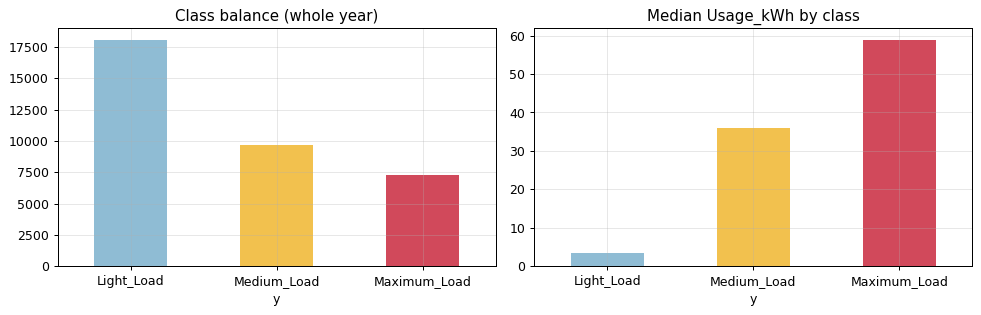

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
df.y.value_counts().reindex(LABELS).plot.bar(ax=ax[0], color=["#8fbcd4", "#f2c14e", "#d1495b"], rot=0)
ax[0].set_title("Class balance (whole year)")
df.groupby("y").usage.median().reindex(LABELS).plot.bar(ax=ax[1], color=["#8fbcd4", "#f2c14e", "#d1495b"], rot=0)
ax[1].set_title("Median Usage_kWh by class"); plt.tight_layout()
print((df.y.value_counts(normalize=True).reindex(LABELS) * 100).round(1).to_string())

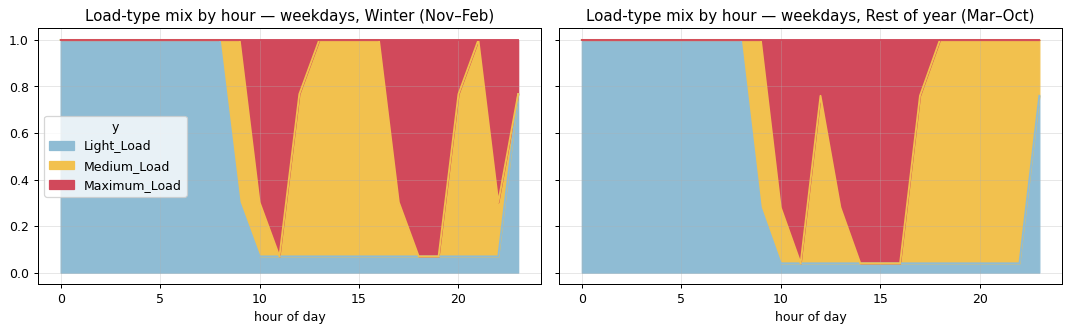

In [7]:
df["hour"] = df.ts.dt.hour + df.ts.dt.minute / 60
df["dow"] = df.ts.dt.dayofweek; df["month"] = df.ts.dt.month; df["slot"] = df.ts.dt.hour * 4 + df.ts.dt.minute // 15
df["winter"] = df.month.isin([11, 12, 1, 2]).astype(int)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, w, name in zip(axes, [1, 0], ["Winter (Nov–Feb)", "Rest of year (Mar–Oct)"]):
    s = df[(df.winter == w) & (df.dow < 5)]
    p = s.groupby([s.ts.dt.hour, "y"]).size().unstack(fill_value=0).reindex(columns=LABELS)
    (p.div(p.sum(axis=1), axis=0)).plot.area(ax=ax, color=["#8fbcd4", "#f2c14e", "#d1495b"], legend=(w == 1))
    ax.set_title(f"Load-type mix by hour — weekdays, {name}"); ax.set_xlabel("hour of day")
plt.tight_layout()

**Key insight:** the label is driven by a **time-of-use tariff schedule that differs between winter and the rest of the year** (the Maximum-load window is mid-day in summer/spring/autumn, but morning + evening in winter), and `Light_Load` takes over on non-working days. A model must therefore know (a) the season/clock position, and (b) whether the plant is actually working today.

In [8]:
day_light = df.groupby(df.ts.dt.date).y.agg(lambda s: (s == "Light_Load").mean())
full_light = day_light[day_light > .99]
print(f"{len(full_light)} days are 100% Light_Load; weekday mix of those days:")
print(pd.Series([pd.Timestamp(d).day_name() for d in full_light.index]).value_counts().to_string())

63 days are 100% Light_Load; weekday mix of those days:
Sunday       35
Saturday     14
Tuesday       4
Monday        3
Wednesday     3
Thursday      2
Friday        2


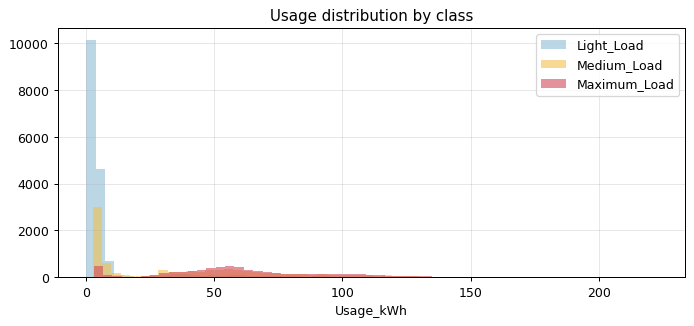

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.6))
d = df.dropna(subset=["usage"]); d = d[d.usage < d.usage.quantile(.995)]
for lab, c in zip(LABELS, ["#8fbcd4", "#f2c14e", "#d1495b"]):
    ax.hist(d[d.y == lab].usage, bins=60, alpha=.6, label=lab, color=c)
ax.set_xlabel("Usage_kWh"); ax.set_title("Usage distribution by class"); ax.legend()

## 4. Feature engineering
All features are computed from the current or earlier rows only (forward-fill, `shift`, trailing rolling windows), so they are valid at prediction time.

| Group | Features | Why |
|---|---|---|
| Raw sensors | usage, lagging/leading kVArh, CO2, lagging/leading PF | the measurements |
| Missing flags | `*_na` | missingness can itself be informative |
| Calendar | hour, slot (0–95), day-of-week, weekend, month, NSM | position in the daily schedule |
| **Season** | `winter` (Nov–Feb) | selects which tariff schedule applies |
| Recent usage | lag-1, lag-4, rolling means (1 h, 3 h, 8 h, 24 h), diff, same-time-yesterday, running mean of the day so far | shows whether the plant is actually operating today |

In [10]:
base = ["usage", "lag_kvarh", "lead_kvarh", "co2", "lag_pf", "lead_pf"]
for c in base:
    df[c + "_na"] = df[c].isna().astype(int)
u = df[base].ffill().usage                      # causal fill, used only for derived features
df["wk"] = (df.dow >= 5).astype(int)
df["u_lag1"], df["u_lag4"] = u.shift(1), u.shift(4)
df["u_diff"] = u.diff()
df["u_roll4"], df["u_roll12"] = u.rolling(4, min_periods=1).mean(), u.rolling(12, min_periods=1).mean()
df["u_roll32"], df["u_roll96"] = u.rolling(32, min_periods=1).mean(), u.rolling(96, min_periods=1).mean()
df["u_prev_day_same"] = u.shift(96)
df["u_day_mean_sofar"] = u.groupby(df.ts.dt.date).expanding().mean().reset_index(level=0, drop=True)

TIME_FEATS = ["hour", "slot", "dow", "wk", "month", "nsm"]
USAGE_FEATS = ["u_lag1", "u_lag4", "u_diff", "u_roll4", "u_roll12", "u_roll32", "u_roll96", "u_prev_day_same", "u_day_mean_sofar"]
FEATURES = base + [c + "_na" for c in base] + TIME_FEATS + ["winter"] + USAGE_FEATS
print(len(FEATURES), "features")

28 features


## 5. Train / test split and model selection

In [11]:
is_test = df.orig >= "2018-12-01"        # last month of the data (incl. its 00:00 end-of-day row)
train, test = df[~is_test].copy(), df[is_test].copy()
print(f"train: {train.ts.min()} → {train.ts.max()}  ({len(train):,} rows)")
print(f"test : {test.ts.min()} → {test.ts.max()}  ({len(test):,} rows)")
print("test class mix:", test.y.value_counts().to_dict())

train: 2018-01-01 00:15:00 → 2018-12-01 00:00:00  (32,064 rows)
test : 2018-12-01 00:15:00 → 2019-01-01 00:00:00  (2,976 rows)
test class mix: {'Light_Load': 1744, 'Medium_Load': 704, 'Maximum_Load': 528}


Model selection uses **expanding-window time-series cross-validation inside the training period only** — the December test set is not touched until the final evaluation.

In [12]:
models = {
    "Logistic regression": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Random forest": RandomForestClassifier(200, n_jobs=-1, class_weight="balanced", random_state=RANDOM_STATE),
    "Hist. gradient boosting": HistGradientBoostingClassifier(max_iter=300, random_state=RANDOM_STATE),
}
tscv = TimeSeriesSplit(n_splits=5)
X_tr, y_tr = train[FEATURES], train.y
rows = []
for name, m in models.items():
    accs, f1s = [], []
    for a, b in tscv.split(X_tr):
        m.fit(X_tr.iloc[a], y_tr.iloc[a]); p = m.predict(X_tr.iloc[b])
        accs.append(accuracy_score(y_tr.iloc[b], p)); f1s.append(f1_score(y_tr.iloc[b], p, average="macro"))
    rows.append((name, np.mean(accs), np.std(accs), np.mean(f1s)))
cv = pd.DataFrame(rows, columns=["model", "cv_accuracy", "cv_acc_std", "cv_macro_f1"]).set_index("model").round(4)
cv

                         cv_accuracy  cv_acc_std  cv_macro_f1
model                                                        
Logistic regression           0.7763      0.0859       0.7174
Random forest                 0.9060      0.1120       0.8796
Hist. gradient boosting       0.9052      0.1119       0.8780


## 6. Final evaluation on the held-out last month (December 2018)

In [13]:
results, preds = {}, {}
for name, m in models.items():
    m.fit(train[FEATURES], train.y); p = m.predict(test[FEATURES]); preds[name] = p
    results[name] = {"accuracy": accuracy_score(test.y, p),
                     "precision (macro)": classification_report(test.y, p, output_dict=True)["macro avg"]["precision"],
                     "recall (macro)": classification_report(test.y, p, output_dict=True)["macro avg"]["recall"],
                     "F1 (macro)": f1_score(test.y, p, average="macro")}
res = pd.DataFrame(results).T.round(4); res

                         accuracy  precision (macro)  recall (macro)  F1 (macro)
Logistic regression        0.7016             0.5793          0.5850      0.5802
Random forest              0.9963             0.9944          0.9946      0.9945
Hist. gradient boosting    0.9993             0.9996          0.9987      0.9992


Best model on the test month: Hist. gradient boosting 

              precision    recall  f1-score   support

  Light_Load     0.9989    1.0000    0.9994      1744
 Medium_Load     1.0000    1.0000    1.0000       704
Maximum_Load     1.0000    0.9962    0.9981       528

    accuracy                         0.9993      2976
   macro avg     0.9996    0.9987    0.9992      2976
weighted avg     0.9993    0.9993    0.9993      2976



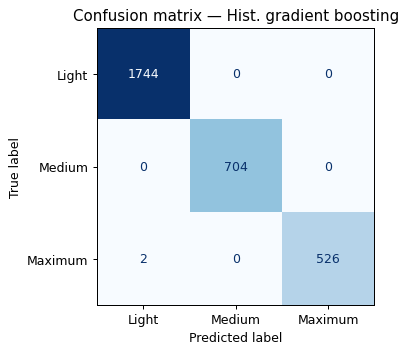

In [14]:
best = res["F1 (macro)"].idxmax(); print("Best model on the test month:", best, "\n")
print(classification_report(test.y, preds[best], labels=LABELS, digits=4))
fig, ax = plt.subplots(figsize=(4.6, 4))
ConfusionMatrixDisplay(confusion_matrix(test.y, preds[best], labels=LABELS), display_labels=["Light", "Medium", "Maximum"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Confusion matrix — {best}"); ax.grid(False)

## 7. What drives the predictions? (ablation)

In [15]:
groups = {
    "Clock only (hour, dow, NSM, month)": TIME_FEATS,
    "Clock + season": TIME_FEATS + ["winter"],
    "Sensors only (no clock/season)": base + [c + "_na" for c in base] + USAGE_FEATS,
    "All features": FEATURES,
}
abl = {}
for g, fs in groups.items():
    m = HistGradientBoostingClassifier(max_iter=300, random_state=RANDOM_STATE).fit(train[fs], train.y); p = m.predict(test[fs])
    abl[g] = {"accuracy": accuracy_score(test.y, p), "F1 (macro)": f1_score(test.y, p, average="macro")}
pd.DataFrame(abl).T.round(4)

                                    accuracy  F1 (macro)
Clock only (hour, dow, NSM, month)    0.8659      0.8621
Clock + season                        0.8619      0.8592
Sensors only (no clock/season)        0.7819      0.6455
All features                          0.9993      0.9992


**Reading the ablation:** clock features (which include `month`, so they already encode the season) get ≈ 87 % — the Medium-vs-Maximum schedule is learned correctly, and the remaining errors are almost all *true Light_Load predicted as Medium/Maximum*, i.e. non-working days that look like normal days on the clock alone. The explicit `winter` flag therefore adds nothing on top of `month` for tree models (it is kept because it is a cleaner, more transferable signal). Sensor/usage features alone are weak (≈ 78 %), because the same usage level occurs in different classes. **Combining both** is what takes accuracy to > 99 %.

Text(0.5, 1.0, 'Random-forest feature importance (top 12)')


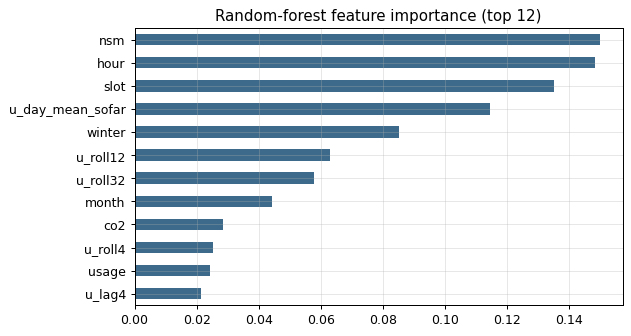

In [16]:
rf = models["Random forest"]
imp = pd.Series(rf.feature_importances_, FEATURES).sort_values().tail(12)
imp.plot.barh(color="#3d6a8a", figsize=(7, 4)); plt.title("Random-forest feature importance (top 12)")

## 8. Conclusions

* **Result:** on the unseen last month (Dec 2018, 2,976 readings) the best model, histogram gradient boosting, reaches **≈ 99.9 % accuracy and macro-F1 ≈ 0.999** (random forest ≈ 99.6 % / 0.995; the logistic-regression baseline only ≈ 70 %). Per-class precision/recall/F1 are in the report above.
* **Why it works:** `Load_Type` follows a seasonal time-of-use tariff plus non-working days. Clock/season features capture the tariff schedule (≈ 87 % alone); trailing-usage features reveal whether the plant is running (non-working days are all Light); together they resolve almost every case.
* **Data fixes mattered:** repairing the mis-dated midnight rows, recomputing the corrupted NSM column, and nulling impossible power factors made the time series consistent — without this, the lag/rolling features would be misaligned.
* **Cross-validation note:** the time-series CV accuracy (≈ 0.91, with high fold variance) is lower than the test score because the early folds are trained on only a few months and have never seen the winter schedule (Nov–Feb) — an expanding window cannot learn a season it has not yet observed. The final model trains on Jan–Nov, which covers winter, so December is in-distribution.
* **Limitations:** a season/schedule that never appears in training cannot be learned, and holidays are only inferred indirectly via low recent usage (the first few intervals of an unexpected non-working day can be mispredicted). An explicit holiday calendar and a full year or more of history would make this more robust.